In [1]:
!pip install -q --upgrade yfinance
import numpy as np
import pandas as pd
import yfinance as yf
from datetime import date, timedelta

print("Ready! yfinance version:", yf.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.3/149.3 kB 5.8 MB/s eta 0:00:00
Ready! yfinance version: 1.7.0


In [10]:
# ticker: (company name, sector, weight)  -> weights must add up to 1.0
PORTFOLIO = {
    "HDFCBANK.NS":   ("HDFC Bank",           "Banking",        0.15),
    "TCS.NS":        ("TCS",                 "IT",             0.15),
    "RELIANCE.NS":   ("Reliance Industries", "Energy",         0.15),
    "SUNPHARMA.NS":  ("Sun Pharma",          "Pharma",         0.10),
    "HINDUNILVR.NS": ("Hindustan Unilever",  "FMCG",           0.10),
    "MARUTI.NS":     ("Maruti Suzuki",       "Auto",           0.10),
    "LT.NS":         ("Larsen & Toubro",     "Infrastructure", 0.15),
    "INFY.NS":       ("Infosys",             "IT",             0.10),
}

BENCHMARK = "NIFTYBEES.NS"      # Nifty 50 ETF (includes dividends, like our stocks)
INITIAL_INVESTMENT = 1_000_000  # Rs 10 lakh
RISK_FREE_RATE = 0.065          # approx. Indian 10-yr govt bond yield
YEARS_OF_HISTORY = 3
TRADING_DAYS = 252              # trading days in a year

total_weight = sum(w for _, _, w in PORTFOLIO.values())
print(f"Stocks: {len(PORTFOLIO)} | Total weight: {total_weight:.2f}")

Stocks: 8 | Total weight: 1.00


In [11]:
end = date.today()
start = end - timedelta(days=365 * YEARS_OF_HISTORY)
tickers = list(PORTFOLIO)

data = yf.download(tickers + [BENCHMARK], start=start, end=end, auto_adjust=True, progress=False)
prices = data["Close"][tickers + [BENCHMARK]]

missing = prices.columns[prices.isna().all()].tolist()
if missing:
    raise ValueError(f"No data for {missing}. Check these ticker symbols.")

prices = prices.ffill().dropna()
prices.index = pd.to_datetime(prices.index).tz_localize(None)
prices.index.name = "Date"

big_moves = (prices.pct_change().abs() > 0.25).any()
for t in big_moves[big_moves].index:
    print(f"WARNING: {t} moved more than 25% in one day. Check for a split or demerger.")

print(f"Downloaded {len(prices)} trading days: {prices.index[0].date()} to {prices.index[-1].date()}")
prices.tail()

Downloaded 738 trading days: 2023-10-13 to 2026-10-09


Ticker,HDFCBANK.NS,TCS.NS,RELIANCE.NS,SUNPHARMA.NS,HINDUNILVR.NS,MARUTI.NS,LT.NS,INFY.NS,NIFTYBEES.NS
Date,,,,,,,,,
2026-10-05,704.799988,2114.399902,1186.400024,1779.699951,1838.400024,11532.0,3750.000000,1020.500000,257.290009
2026-10-06,711.450012,2100.000000,1218.000000,1804.099976,1895.199951,11625.0,3770.000000,1013.849976,258.890015
2026-10-07,702.750000,2080.300049,1207.699951,1781.000000,1865.400024,11450.0,3701.500000,992.000000,257.589996
2026-10-08,692.250000,2076.000000,1178.000000,1759.800049,1844.500000,11228.0,3625.100098,997.000000,253.759995
2026-10-09,707.250000,2156.000000,1170.300049,1760.000000,1856.699951,11420.0,3703.300049,1023.400024,257.350006


Day 1 value:  Rs 1,000,000
Latest value: Rs 1,002,305
Same money in NIFTY 50: Rs 1,180,126


<Axes: title={'center': 'Growth of Rs 10 lakh'}, xlabel='Date'>

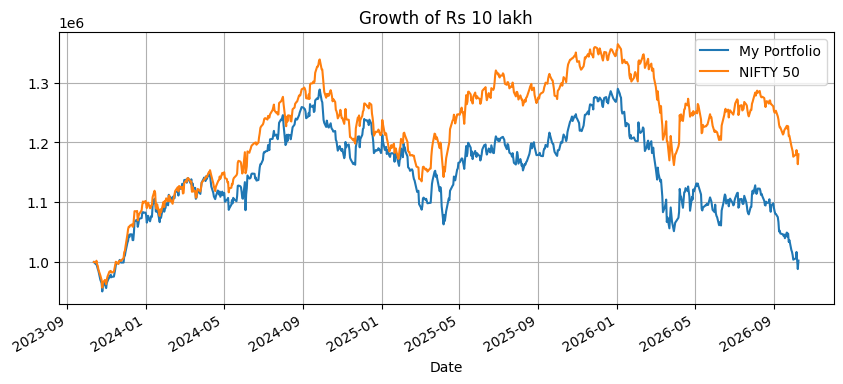

In [12]:
stock_prices = prices[tickers]
benchmark_prices = prices[BENCHMARK]

# How many shares of each stock our money buys on day one
shares = pd.Series({t: INITIAL_INVESTMENT * PORTFOLIO[t][2] / stock_prices[t].iloc[0] for t in tickers})

stock_values = stock_prices * shares                  # daily value of each holding
portfolio_value = stock_values.sum(axis=1)            # daily total portfolio value
benchmark_value = INITIAL_INVESTMENT * benchmark_prices / benchmark_prices.iloc[0]
benchmark_returns = benchmark_value.pct_change().dropna()

print(f"Day 1 value:  Rs {portfolio_value.iloc[0]:,.0f}")
print(f"Latest value: Rs {portfolio_value.iloc[-1]:,.0f}")
print(f"Same money in NIFTY 50: Rs {benchmark_value.iloc[-1]:,.0f}")

pd.DataFrame({"My Portfolio": portfolio_value, "NIFTY 50": benchmark_value}).plot(
    figsize=(10, 4), title="Growth of Rs 10 lakh", grid=True)

In [13]:
def calc_metrics(values, benchmark_returns=None):
    daily_returns = values.pct_change().dropna()
    total_return = values.iloc[-1] / values.iloc[0] - 1
    years = (values.index[-1] - values.index[0]).days / 365.25
    cagr = (1 + total_return) ** (1 / years) - 1
    volatility = daily_returns.std() * np.sqrt(TRADING_DAYS)
    sharpe = (cagr - RISK_FREE_RATE) / volatility
    max_drawdown = (values / values.cummax() - 1).min()

    beta = np.nan
    if benchmark_returns is not None:
        both = pd.concat([daily_returns, benchmark_returns], axis=1, join="inner").dropna()
        beta = both.iloc[:, 0].cov(both.iloc[:, 1]) / both.iloc[:, 1].var()

    return {"Total_Return": total_return, "CAGR": cagr, "Volatility": volatility,
            "Sharpe_Ratio": sharpe, "Max_Drawdown": max_drawdown, "Beta": beta}

print("Metrics calculator ready!")

Metrics calculator ready!


In [14]:
port_m = calc_metrics(portfolio_value, benchmark_returns)
bench_m = calc_metrics(benchmark_value, benchmark_returns)

# Table 1: Portfolio vs NIFTY 50
pct_rows = ["Total_Return", "CAGR", "Volatility", "Max_Drawdown"]
print(f"{'Metric':<15}{'Portfolio':>12}{'NIFTY 50':>12}")
print("-" * 39)
for k in port_m:
    if k in pct_rows:
        print(f"{k:<15}{port_m[k]:>12.1%}{bench_m[k]:>12.1%}")
    else:
        print(f"{k:<15}{port_m[k]:>12.2f}{bench_m[k]:>12.2f}")

# Table 2: Each stock
rows = []
for t in tickers:
    company, sector, weight = PORTFOLIO[t]
    m = calc_metrics(stock_values[t], benchmark_returns)
    rows.append({"Ticker": t, "Company": company, "Sector": sector,
                 "Starting_Weight": weight,
                 "Current_Weight": stock_values[t].iloc[-1] / portfolio_value.iloc[-1],
                 "Invested": INITIAL_INVESTMENT * weight,
                 "Current_Value": stock_values[t].iloc[-1], **m})
stock_summary = pd.DataFrame(rows)

stock_summary[["Company", "Sector", "Total_Return", "Volatility", "Sharpe_Ratio", "Beta"]] \
    .sort_values("Total_Return", ascending=False).round(2)

Metric            Portfolio    NIFTY 50
---------------------------------------
Total_Return           0.2%       18.0%
CAGR                   0.1%        5.7%
Volatility            13.5%       12.1%
Sharpe_Ratio          -0.48       -0.07
Max_Drawdown         -23.4%      -15.2%
Beta                   1.00        1.00


,Company,Sector,Total_Return,Volatility,Sharpe_Ratio,Beta
3,Sun Pharma,Pharma,0.58,0.20,0.51,0.55
6,Larsen & Toubro,Infrastructure,0.23,0.26,0.03,1.48
5,Maruti Suzuki,Auto,0.10,0.22,-0.15,1.00
2,Reliance Industries,Energy,0.01,0.21,-0.29,1.17
0,HDFC Bank,Banking,-0.04,0.20,-0.38,1.13
7,Infosys,IT,-0.21,0.26,-0.54,0.92
4,Hindustan Unilever,FMCG,-0.24,0.20,-0.74,0.56
1,TCS,IT,-0.34,0.24,-0.81,0.84


In [16]:
RF_DAILY = (1 + RISK_FREE_RATE) ** (1 / TRADING_DAYS) - 1   # risk-free rate per trading day

def calc_metrics_pro(values, bench_values=None):
    r = values.pct_change().dropna()                 # daily returns
    excess = r - RF_DAILY                            # return above the risk-free rate
    years = (values.index[-1] - values.index[0]).days / 365.25
    total_return = values.iloc[-1] / values.iloc[0] - 1
    cagr = (1 + total_return) ** (1 / years) - 1
    vol = r.std() * np.sqrt(TRADING_DAYS)
    downside_vol = np.sqrt((np.minimum(excess, 0) ** 2).mean()) * np.sqrt(TRADING_DAYS)
    max_dd = (values / values.cummax() - 1).min()
    var_95 = -np.percentile(r, 5)

    m = {"Total_Return": total_return, "CAGR": cagr, "Volatility": vol,
         "Sharpe_Ratio": excess.mean() * TRADING_DAYS / vol,
         "Sortino_Ratio": excess.mean() * TRADING_DAYS / downside_vol,
         "Max_Drawdown": max_dd, "Calmar_Ratio": cagr / abs(max_dd),
         "VaR_95_1D": var_95, "CVaR_95_1D": -r[r <= -var_95].mean(),
         "Best_Day": r.max(), "Worst_Day": r.min(), "Positive_Days": (r > 0).mean()}

    if bench_values is not None:                     # market-relative metrics
        b = bench_values.pct_change().dropna()
        df = pd.concat([r, b], axis=1, join="inner").dropna()
        df.columns = ["p", "b"]
        beta = df.p.cov(df.b) / df.b.var()
        alpha = ((df.p - RF_DAILY).mean() - beta * (df.b - RF_DAILY).mean()) * TRADING_DAYS
        active = df.p - df.b
        te = active.std() * np.sqrt(TRADING_DAYS)
        up, down = df.b > 0, df.b < 0
        m.update({"Beta": beta, "Alpha_Annual": alpha, "R_Squared": df.p.corr(df.b) ** 2,
                  "Tracking_Error": te, "Information_Ratio": active.mean() * TRADING_DAYS / te,
                  "Upside_Capture": df.p[up].mean() / df.b[up].mean(),
                  "Downside_Capture": df.p[down].mean() / df.b[down].mean()})
    return m

port_m = calc_metrics_pro(portfolio_value, benchmark_value)
bench_m = calc_metrics_pro(benchmark_value)

PCT = {"Total_Return", "CAGR", "Volatility", "Max_Drawdown", "VaR_95_1D", "CVaR_95_1D",
       "Best_Day", "Worst_Day", "Positive_Days", "Alpha_Annual", "Tracking_Error"}
fmt = lambda k, v: "-" if pd.isna(v) else (f"{v:.2%}" if k in PCT else f"{v:.2f}")
scorecard = pd.DataFrame({"Portfolio": port_m, "Benchmark": bench_m})
display(pd.DataFrame({c: [fmt(k, v) for k, v in scorecard[c].items()] for c in scorecard},
                     index=scorecard.index))

,Portfolio,Benchmark
Total_Return,0.23%,18.01%
CAGR,0.08%,5.70%
Volatility,13.47%,12.06%
Sharpe_Ratio,-0.39,0.01
Sortino_Ratio,-0.55,0.01
Max_Drawdown,-23.38%,-15.23%
Calmar_Ratio,0.00,0.37
VaR_95_1D,1.43%,1.18%
CVaR_95_1D,1.93%,1.71%
Best_Day,3.55%,3.90%


In [17]:
rows = []
for t in tickers:
    company, sector, weight = PORTFOLIO[t]
    rows.append({"Ticker": t, "Company": company, "Sector": sector,
                 "Starting_Weight": weight,
                 "Current_Weight": stock_values[t].iloc[-1] / portfolio_value.iloc[-1],
                 "Invested": INITIAL_INVESTMENT * weight,
                 "Current_Value": stock_values[t].iloc[-1],
                 "Profit": stock_values[t].iloc[-1] - INITIAL_INVESTMENT * weight,
                 "Return_Contribution": (stock_values[t].iloc[-1] - INITIAL_INVESTMENT * weight) / INITIAL_INVESTMENT,
                 **calc_metrics_pro(stock_values[t], benchmark_value)})
stock_summary = pd.DataFrame(rows)

print(f"Return contributions add up to {stock_summary.Return_Contribution.sum():.2%} "
      f"(portfolio total return: {port_m['Total_Return']:.2%})")
display(stock_summary[["Company", "Return_Contribution", "Sharpe_Ratio", "Sortino_Ratio", "Beta", "Alpha_Annual"]]
        .sort_values("Return_Contribution", ascending=False).round(3))

Return contributions add up to 0.23% (portfolio total return: 0.23%)


,Company,Return_Contribution,Sharpe_Ratio,Sortino_Ratio,Beta,Alpha_Annual
3,Sun Pharma,0.058,0.571,0.828,0.553,0.112
6,Larsen & Toubro,0.035,0.160,0.224,1.478,0.040
5,Maruti Suzuki,0.010,-0.028,-0.041,1.001,-0.007
2,Reliance Industries,0.001,-0.177,-0.253,1.174,-0.039
0,HDFC Bank,-0.006,-0.271,-0.367,1.130,-0.056
7,Infosys,-0.021,-0.418,-0.596,0.917,-0.111
4,Hindustan Unilever,-0.024,-0.657,-0.898,0.563,-0.134
1,TCS,-0.051,-0.737,-1.029,0.840,-0.176


486 days of rolling metrics, from 2024-10-24
Beta ranged from 0.95 to 1.04


<Axes: title={'center': '1-Year Rolling Volatility'}, xlabel='Date'>

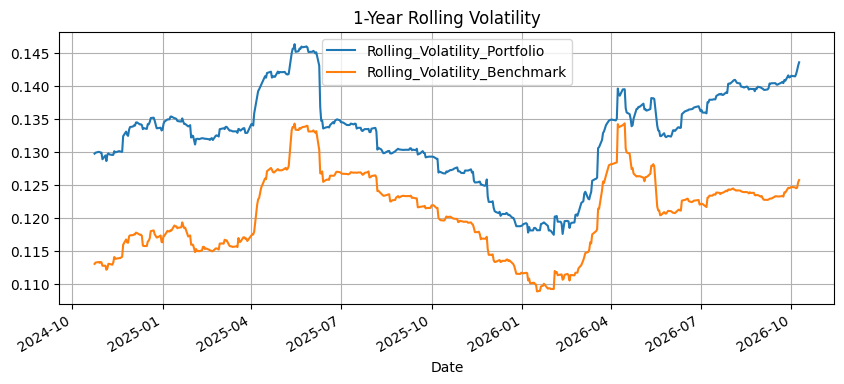

In [18]:
WINDOW = TRADING_DAYS                       # 1-year rolling window
p_ret = portfolio_value.pct_change()
b_ret = benchmark_value.pct_change()
p_vol = p_ret.rolling(WINDOW).std() * np.sqrt(TRADING_DAYS)

rolling_metrics = pd.DataFrame({
    "Rolling_1Y_Return_Portfolio": portfolio_value.pct_change(WINDOW),
    "Rolling_1Y_Return_Benchmark": benchmark_value.pct_change(WINDOW),
    "Rolling_Volatility_Portfolio": p_vol,
    "Rolling_Volatility_Benchmark": b_ret.rolling(WINDOW).std() * np.sqrt(TRADING_DAYS),
    "Rolling_Sharpe_Portfolio": (p_ret - RF_DAILY).rolling(WINDOW).mean() * TRADING_DAYS / p_vol,
    "Rolling_Beta": p_ret.rolling(WINDOW).cov(b_ret) / b_ret.rolling(WINDOW).var(),
}).dropna().reset_index()

print(f"{len(rolling_metrics)} days of rolling metrics, from {rolling_metrics.Date.iloc[0].date()}")
print(f"Beta ranged from {rolling_metrics.Rolling_Beta.min():.2f} to {rolling_metrics.Rolling_Beta.max():.2f}")
rolling_metrics.set_index("Date")[["Rolling_Volatility_Portfolio", "Rolling_Volatility_Benchmark"]].plot(
    figsize=(10, 4), title="1-Year Rolling Volatility", grid=True)

In [19]:
stock_returns = stock_prices.pct_change().dropna()
cov_annual = stock_returns.cov() * TRADING_DAYS                # how stocks move together (yearly)
w = stock_values.iloc[-1] / portfolio_value.iloc[-1]           # today's weights

port_vol_now = np.sqrt(w @ cov_annual @ w)                     # portfolio risk at today's weights
risk_contrib = w * (cov_annual @ w) / port_vol_now             # each stock's share of that risk
stand_alone_vol = stock_returns.std() * np.sqrt(TRADING_DAYS)

risk_contribution = pd.DataFrame({
    "Ticker": tickers,
    "Company": [PORTFOLIO[t][0] for t in tickers],
    "Sector": [PORTFOLIO[t][1] for t in tickers],
    "Weight": w.values,
    "Risk_Contribution": (risk_contrib / port_vol_now).values,
})
risk_contribution["Risk_vs_Weight"] = risk_contribution.Risk_Contribution - risk_contribution.Weight

names = {t: PORTFOLIO[t][0] for t in tickers}
corr = stock_returns.corr().rename(index=names, columns=names)
n = len(tickers)
avg_corr = (corr.values.sum() - n) / (n * (n - 1))
diversification_ratio = (w * stand_alone_vol).sum() / port_vol_now

corr.index.name, corr.columns.name = "Stock_1", None
correlation_long = corr.reset_index().melt(id_vars="Stock_1", var_name="Stock_2", value_name="Correlation")

print(f"Portfolio volatility at today's weights: {port_vol_now:.2%}")
print(f"Average correlation between stocks:     {avg_corr:.2f}")
print(f"Diversification ratio:                  {diversification_ratio:.2f}")
display(risk_contribution[["Company", "Weight", "Risk_Contribution", "Risk_vs_Weight"]]
        .sort_values("Risk_Contribution", ascending=False).round(3))

Portfolio volatility at today's weights: 13.57%
Average correlation between stocks:     0.25
Diversification ratio:                  1.65


,Company,Weight,Risk_Contribution,Risk_vs_Weight
6,Larsen & Toubro,0.184,0.266,0.081
2,Reliance Industries,0.151,0.167,0.016
0,HDFC Bank,0.144,0.133,-0.011
3,Sun Pharma,0.158,0.112,-0.046
5,Maruti Suzuki,0.109,0.106,-0.004
1,TCS,0.099,0.096,-0.003
7,Infosys,0.078,0.079,0.001
4,Hindustan Unilever,0.076,0.042,-0.034


In [20]:
def monthly_returns(values):
    month_end = values.groupby(values.index.to_period("M")).last()
    r = month_end.pct_change()
    r.iloc[0] = month_end.iloc[0] / values.iloc[0] - 1        # first (partial) month
    return r

monthly = pd.DataFrame({"Portfolio_Return": monthly_returns(portfolio_value),
                        "Benchmark_Return": monthly_returns(benchmark_value)})
monthly["Excess_Return"] = monthly.Portfolio_Return - monthly.Benchmark_Return
monthly["Year"] = monthly.index.year
monthly["Month_Num"] = monthly.index.month
monthly["Month"] = monthly.index.strftime("%b")
monthly["Month_Start"] = monthly.index.to_timestamp()
monthly_returns_table = monthly.reset_index(drop=True)

print(f"Months beating the benchmark: {(monthly.Excess_Return > 0).sum()} of {len(monthly)}")
print(f"Best month:  {monthly.Portfolio_Return.max():.1%}   Worst month: {monthly.Portfolio_Return.min():.1%}")
heatmap = monthly.pivot(index="Year", columns="Month_Num", values="Portfolio_Return")
heatmap.columns = [pd.Timestamp(2000, m, 1).strftime("%b") for m in heatmap.columns]
display(heatmap.style.format("{:.1%}", na_rep="").background_gradient(cmap="RdYlGn", axis=None))

Months beating the benchmark: 14 of 37
Best month:  7.1%   Worst month: -10.7%


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Year,,,,,,,,,,,,
2023,,,,,,,,,,-4.0%,5.3%,7.1%
2024,0.6%,3.1%,0.9%,-1.9%,-0.5%,5.2%,6.8%,1.4%,0.9%,-6.7%,1.7%,-1.9%
2025,0.7%,-7.8%,3.9%,2.3%,1.2%,1.9%,-2.0%,0.0%,-0.1%,5.3%,2.9%,-0.3%
2026,-5.5%,-2.0%,-10.7%,6.3%,-2.8%,0.7%,1.8%,-1.4%,-7.9%,-0.9%,,


In [21]:
TRANSACTION_COST = 0.002          # ~0.2% of every rupee traded (STT, brokerage, charges) - an assumption
target = pd.Series({t: PORTFOLIO[t][2] for t in tickers})
daily_r = stock_prices.pct_change().fillna(0)

holdings = INITIAL_INVESTMENT * target
values, total_costs, rebalances = [], 0.0, 0
prev_q = stock_prices.index[0].to_period("Q")
for d in stock_prices.index:
    holdings = holdings * (1 + daily_r.loc[d])            # let prices move
    q = d.to_period("Q")
    if q != prev_q:                                        # first trading day of a new quarter
        new_holdings = holdings.sum() * target             # reset to target weights
        cost = (new_holdings - holdings).abs().sum() * TRANSACTION_COST
        holdings = (holdings.sum() - cost) * target
        total_costs += cost
        rebalances += 1
        prev_q = q
    values.append(holdings.sum())
rebalanced_value = pd.Series(values, index=stock_prices.index)

rebal_m = calc_metrics_pro(rebalanced_value, benchmark_value)
compare = ["Total_Return", "CAGR", "Volatility", "Sharpe_Ratio", "Max_Drawdown", "Beta"]
print(f"Rebalanced {rebalances} times, total trading costs: Rs {total_costs:,.0f}\n")
print(f"{'Metric':<15}{'Buy & Hold':>12}{'Rebalanced':>12}")
for k in compare:
    f = ".1%" if k in PCT else ".2f"
    print(f"{k:<15}{port_m[k]:>12{f}}{rebal_m[k]:>12{f}}")

Rebalanced 12 times, total trading costs: Rs 2,111

Metric           Buy & Hold  Rebalanced
Total_Return           0.2%        2.1%
CAGR                   0.1%        0.7%
Volatility            13.5%       13.6%
Sharpe_Ratio          -0.39       -0.34
Max_Drawdown         -23.4%      -23.7%
Beta                   1.00        0.99


My Portfolio    Return   1.5% | Risk  13.6% | Sharpe -0.37
Minimum Risk    Return   2.6% | Risk  12.2% | Sharpe -0.32
Maximum Sharpe  Return  12.3% | Risk  16.4% | Sharpe 0.35


,Company,My_Portfolio,Minimum_Risk,Maximum_Sharpe
0,HDFC Bank,0.15,0.191,0.0
1,TCS,0.15,0.105,0.0
2,Reliance Industries,0.15,0.074,0.0
3,Sun Pharma,0.10,0.266,0.4
4,Hindustan Unilever,0.10,0.230,0.0
5,Maruti Suzuki,0.10,0.097,0.2
6,Larsen & Toubro,0.15,0.000,0.4
7,Infosys,0.10,0.038,0.0


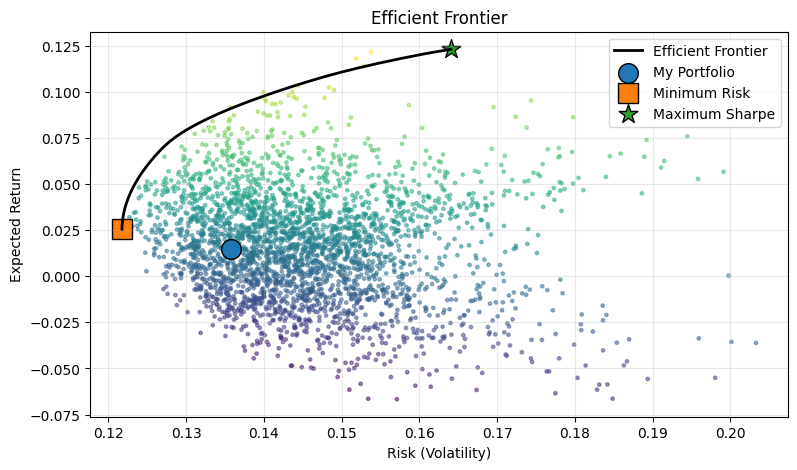

In [22]:
from scipy.optimize import minimize

MAX_WEIGHT = 0.40                                  # no single stock above 40% (a common risk limit)
mu = stock_returns.mean() * TRADING_DAYS           # expected yearly return of each stock (historical)
cov = cov_annual
port_ret = lambda wt: wt @ mu
port_vol = lambda wt: np.sqrt(wt @ cov @ wt)
sharpe = lambda wt: (port_ret(wt) - RISK_FREE_RATE) / port_vol(wt)

bounds = [(0, MAX_WEIGHT)] * n                     # no short selling
fully_invested = {"type": "eq", "fun": lambda wt: wt.sum() - 1}
start_w = np.repeat(1 / n, n)
solve = lambda f, cons: minimize(f, start_w, method="SLSQP", bounds=bounds, constraints=cons)

w_minvar = solve(port_vol, [fully_invested]).x
w_maxsharpe = solve(lambda wt: -sharpe(wt), [fully_invested]).x
max_ret = port_ret(solve(lambda wt: -port_ret(wt), [fully_invested]).x)

# The efficient frontier: lowest possible risk for each level of return
frontier = []
for target_ret in np.linspace(port_ret(w_minvar), max_ret, 40):
    res = solve(port_vol, [fully_invested, {"type": "eq", "fun": lambda wt, r=target_ret: port_ret(wt) - r}])
    if res.success:
        frontier.append({"Type": "Efficient Frontier", "Return": target_ret, "Volatility": res.fun})

# 3,000 random portfolios to show the "cloud" of possible choices
rng = np.random.default_rng(42)
for wt in rng.dirichlet(np.ones(n), 3000):
    frontier.append({"Type": "Random Portfolio", "Return": port_ret(wt), "Volatility": port_vol(wt)})

key = {"My Portfolio": target.values, "Minimum Risk": w_minvar, "Maximum Sharpe": w_maxsharpe}
for label, wt in key.items():
    frontier.append({"Type": label, "Return": port_ret(wt), "Volatility": port_vol(wt)})
frontier_points = pd.DataFrame(frontier)
frontier_points["Sharpe_Ratio"] = (frontier_points.Return - RISK_FREE_RATE) / frontier_points.Volatility

optimal_weights = pd.DataFrame({"Ticker": tickers, "Company": [PORTFOLIO[t][0] for t in tickers],
                                "Sector": [PORTFOLIO[t][1] for t in tickers],
                                "My_Portfolio": target.values,
                                "Minimum_Risk": w_minvar.round(4), "Maximum_Sharpe": w_maxsharpe.round(4)})

for label, wt in key.items():
    print(f"{label:<15} Return {port_ret(wt):6.1%} | Risk {port_vol(wt):6.1%} | Sharpe {sharpe(wt):.2f}")
display(optimal_weights[["Company", "My_Portfolio", "Minimum_Risk", "Maximum_Sharpe"]].round(3))

import matplotlib.pyplot as plt
fp = frontier_points
plt.figure(figsize=(9, 5))
cloud = fp[fp.Type == "Random Portfolio"]
plt.scatter(cloud.Volatility, cloud.Return, c=cloud.Sharpe_Ratio, cmap="viridis", s=6, alpha=0.5)
line = fp[fp.Type == "Efficient Frontier"]
plt.plot(line.Volatility, line.Return, "k-", lw=2, label="Efficient Frontier")
for label, marker in zip(key, ["o", "s", "*"]):
    pt = fp[fp.Type == label]
    plt.scatter(pt.Volatility, pt.Return, marker=marker, s=200, edgecolor="k", label=label)
plt.xlabel("Risk (Volatility)"); plt.ylabel("Expected Return"); plt.title("Efficient Frontier")
plt.legend(); plt.grid(alpha=0.3); plt.show()

Starting value today:                 Rs 1,002,305
Median value in 1 year:               Rs 1,030,934
Bad case (5% of outcomes are worse):  Rs 825,342
Good case (5% of outcomes are better): Rs 1,284,180
Chance of losing money:               41.9%
Chance of beating a 6.5% bond:        39.6%


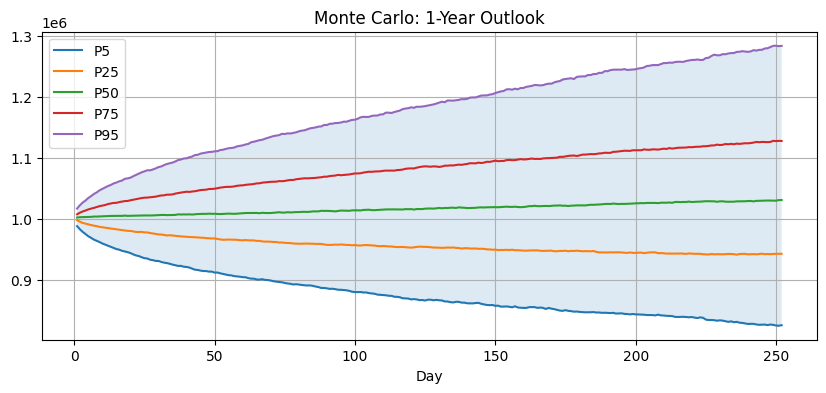

In [23]:
N_SIMS, HORIZON = 10_000, TRADING_DAYS              # 10,000 possible futures, 1 year each
daily_port = stock_returns.values @ w.values        # history of daily returns at today's weights

rng = np.random.default_rng(7)
picks = rng.integers(0, len(daily_port), size=(N_SIMS, HORIZON))   # randomly re-draw real past days
start_value = portfolio_value.iloc[-1]
paths = start_value * np.cumprod(1 + daily_port[picks], axis=1)
ending = paths[:, -1]

pcts = [5, 25, 50, 75, 95]
bands = np.percentile(paths, pcts, axis=0)
monte_carlo_paths = pd.DataFrame({"Day": np.arange(1, HORIZON + 1),
                                  **{f"P{p}": bands[i] for i, p in enumerate(pcts)}})

counts, edges = np.histogram(ending, bins=40)
monte_carlo_distribution = pd.DataFrame({"Ending_Value": (edges[:-1] + edges[1:]) / 2, "Simulations": counts})

mc = {"MC_Start_Value": start_value,
      "MC_Median_Value": np.median(ending),
      "MC_Worst_5pct_Value": np.percentile(ending, 5),
      "MC_Best_5pct_Value": np.percentile(ending, 95),
      "MC_Prob_Loss": (ending < start_value).mean(),
      "MC_Prob_Beat_RiskFree": (ending > start_value * (1 + RISK_FREE_RATE)).mean()}

print(f"Starting value today:                 Rs {start_value:,.0f}")
print(f"Median value in 1 year:               Rs {mc['MC_Median_Value']:,.0f}")
print(f"Bad case (5% of outcomes are worse):  Rs {mc['MC_Worst_5pct_Value']:,.0f}")
print(f"Good case (5% of outcomes are better): Rs {mc['MC_Best_5pct_Value']:,.0f}")
print(f"Chance of losing money:               {mc['MC_Prob_Loss']:.1%}")
print(f"Chance of beating a {RISK_FREE_RATE:.1%} bond:        {mc['MC_Prob_Beat_RiskFree']:.1%}")

ax = monte_carlo_paths.set_index("Day").plot(figsize=(10, 4), title="Monte Carlo: 1-Year Outlook", grid=True)
ax.fill_between(monte_carlo_paths.Day, monte_carlo_paths.P5, monte_carlo_paths.P95, alpha=0.15)

In [24]:
import os, shutil
from google.colab import files

# 1. Daily time series: portfolio, rebalanced strategy, benchmark
timeseries = pd.DataFrame({
    "Portfolio_Value": portfolio_value, "Rebalanced_Value": rebalanced_value,
    "Benchmark_Value": benchmark_value,
    "Portfolio_Cumulative_Return": portfolio_value / portfolio_value.iloc[0] - 1,
    "Rebalanced_Cumulative_Return": rebalanced_value / rebalanced_value.iloc[0] - 1,
    "Benchmark_Cumulative_Return": benchmark_value / benchmark_value.iloc[0] - 1,
    "Portfolio_Drawdown": portfolio_value / portfolio_value.cummax() - 1,
    "Benchmark_Drawdown": benchmark_value / benchmark_value.cummax() - 1,
}).reset_index()

# 2. Sector split
sector_allocation = (stock_summary.groupby("Sector", as_index=False)
    .agg(Starting_Weight=("Starting_Weight", "sum"), Current_Weight=("Current_Weight", "sum"),
         Current_Value=("Current_Value", "sum"), Return_Contribution=("Return_Contribution", "sum"))
    .merge(risk_contribution.groupby("Sector", as_index=False)["Risk_Contribution"].sum(), on="Sector")
    .sort_values("Current_Value", ascending=False))

# 3. Headline KPIs in one row (for cards)
kpis = {"Start_Date": prices.index[0].date(), "End_Date": prices.index[-1].date(),
        "Initial_Investment": INITIAL_INVESTMENT, "Final_Value": portfolio_value.iloc[-1],
        "Outperformance": port_m["Total_Return"] - bench_m["Total_Return"],
        "Diversification_Ratio": diversification_ratio, "Average_Correlation": avg_corr}
kpis.update({f"Portfolio_{k}": v for k, v in port_m.items()})
kpis.update({f"Benchmark_{k}": v for k, v in bench_m.items()})
kpis.update({f"Rebalanced_{k}": v for k, v in rebal_m.items()})
kpis.update(mc)
kpi_summary = pd.DataFrame([kpis])

# 4. Scorecard in long format (for a comparison table)
scorecard_long = pd.DataFrame({"Buy_and_Hold": port_m, "Rebalanced": rebal_m, "Benchmark": bench_m})
scorecard_long["Is_Percent"] = scorecard_long.index.isin(PCT)
scorecard_long = scorecard_long.rename_axis("Metric").reset_index()

# 5. Daily value of each holding (long format)
daily_stock_values = stock_values.reset_index().melt(id_vars="Date", var_name="Ticker", value_name="Holding_Value")
daily_stock_values["Sector"] = daily_stock_values.Ticker.map(lambda t: PORTFOLIO[t][1])

# 6. Assumptions, so anyone can see exactly how the model works
assumptions = pd.DataFrame({"Item": [
    "Data source", "Period", "Initial investment", "Benchmark", "Risk-free rate",
    "Strategy", "Rebalanced strategy", "Transaction cost", "Efficient frontier",
    "Monte Carlo", "Not included", "Disclaimer"], "Value": [
    "Yahoo Finance daily prices, adjusted for splits and dividends",
    f"{prices.index[0].date()} to {prices.index[-1].date()}",
    f"Rs {INITIAL_INVESTMENT:,.0f}",
    f"{BENCHMARK} (Nifty 50 ETF, dividends reinvested)",
    f"{RISK_FREE_RATE:.1%} per year",
    "Buy and hold, invested on day one at target weights",
    "Reset to target weights at the start of every quarter",
    f"{TRANSACTION_COST:.2%} of value traded",
    f"Historical returns, long-only, max {MAX_WEIGHT:.0%} per stock; hindsight-based, not a forecast",
    f"{N_SIMS:,} one-year paths, bootstrapped from historical daily returns at current weights",
    "Taxes, cash drag, intraday prices",
    "Sample portfolio for learning purposes only, not investment advice"]})

outputs = {
    "portfolio_timeseries.csv": timeseries, "stock_summary.csv": stock_summary,
    "sector_allocation.csv": sector_allocation, "kpi_summary.csv": kpi_summary,
    "scorecard.csv": scorecard_long, "daily_stock_values.csv": daily_stock_values,
    "rolling_metrics.csv": rolling_metrics, "risk_contribution.csv": risk_contribution,
    "correlation_matrix.csv": correlation_long, "monthly_returns.csv": monthly_returns_table,
    "efficient_frontier.csv": frontier_points, "optimal_weights.csv": optimal_weights,
    "monte_carlo_paths.csv": monte_carlo_paths, "monte_carlo_distribution.csv": monte_carlo_distribution,
    "assumptions.csv": assumptions,
}
shutil.rmtree("powerbi_data", ignore_errors=True)
os.makedirs("powerbi_data")
for name, df in outputs.items():
    df.to_csv(f"powerbi_data/{name}", index=False, date_format="%Y-%m-%d")
    print(f"Saved {name:<30} {len(df):>7,} rows")

shutil.make_archive("powerbi_data_pro", "zip", "powerbi_data")
files.download("powerbi_data_pro.zip")

Saved portfolio_timeseries.csv           738 rows
Saved stock_summary.csv                    8 rows
Saved sector_allocation.csv                7 rows
Saved kpi_summary.csv                      1 rows
Saved scorecard.csv                       19 rows
Saved daily_stock_values.csv           5,904 rows
Saved rolling_metrics.csv                486 rows
Saved risk_contribution.csv                8 rows
Saved correlation_matrix.csv              64 rows
Saved monthly_returns.csv                 37 rows
Saved efficient_frontier.csv           3,043 rows
Saved optimal_weights.csv                  8 rows
Saved monte_carlo_paths.csv              252 rows
Saved monte_carlo_distribution.csv        40 rows
Saved assumptions.csv                     12 rows


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>